# Matrix factorization: multiple seeds with GALAHAD GLRT cubic Newton

Section 5.2 / Appendix E.2 of [Skip the Hessian, Keep the Rates](https://arxiv.org/abs/2602.08069v1).
This notebook follows the original sequence: run the methods for each seed,
average their histories, and plot the results. It uses the corrected oracle
with the revised equation (27):

$$F(U,V)=\frac12\|UV-M_{\mathrm{obs}}\|_F^2
  +\frac{\alpha}{2}(\|U\|_F^2+\|V\|_F^2)
  +\frac{\beta}{2}(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$

Here $U\in\mathbb{R}^{m\times r}$, $V\in\mathbb{R}^{r\times n}$, and
$(-U)_+=\max(-U,0)$ entrywise. The nonnegativity condition is penalized;
the factors are not constrained to be nonnegative at every iterate.

`M_obs` is the observed data matrix of shape `(m, n)` that the product `U @ V`
is fitted to. In this synthetic experiment, `M_clean = U_true @ V_true`,
where `U_true` has shape `(m, r)` and `V_true` has shape `(r, n)`, with
independent entries drawn uniformly from `[0, 1)`. We then generate
`M_obs = M_clean + noise * np.random.randn(m, n)`, adding independent
zero-mean Gaussian noise with standard deviation `noise` to each entry.
When `noise = 0`, `M_obs` equals `M_clean`; with nonzero noise, observed
entries can be negative. `M_obs` stays fixed during optimization and is
shared by all methods within a seed; the solvers update only `U` and `V`.


This notebook copies `experiment_matrix_factorization_multiple_new.ipynb` and adds
the new nonconvex cubic Newton baseline. Existing data generation, seed order,
initial factors, GD/LeAP/GLAd settings, averaging, and plot layout are preserved.

The cubic subproblem backend is now GALAHAD GLRT. Stored outputs from the
previous custom solver were archived locally before clearing this notebook;
run all cells again to produce GLRT curves. This is an additional comparison,
not a reproduction of a published cubic-baseline figure.


In [73]:
import sys
from pathlib import Path
from datetime import datetime

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton_nonconvex_new
from oracles_mat_fac import PositiveMatrixFactorization
from utils_new import run_methods, plot_figures

%matplotlib inline

## Parameters

| Variable | Meaning |
| --- | --- |
| `seeds_to_try` | Each seed fixes both the synthetic data and the starting factors. All methods use the same data and start within a seed. |
| `m`, `n`, `r` | Number of rows, number of columns, and factorization rank. |
| `noise` | Standard deviation of independent Gaussian noise added to `M_clean = U_true @ V_true`. The true factors have entries uniform on [0, 1). |
| `alpha`, `beta` | Ridge and nonnegativity weights in the objective above, each with a factor of 1/2. |
| `initial_factor_std` | Standard deviation of the zero-mean Gaussian entries of `U_0` and `V_0`. These starting factors can have negative entries. |
| `gradient_iterations`, `number_of_iterations` | Maximum outer iterations for gradient descent and each Newton method, respectively. |
| `initial_lambda` | Initial regularization passed as `H_0` to LeAP and GLAd. Both start with this actual shift in `Hessian + lambda * I`; GLAd subsequently scales its shift with the gradient norm raised to `p`. |
| `lss_method`, `lss_tol`, `lss_maxiters` | Linear subproblem solver, its requested relative tolerance, and its maximum iterations per solve. |
| `cubic_initial_H` | Initial cubic parameter: the model uses `cubic_initial_H / 6 * ||step||**3`. This is distinct from the LeAP/GLAd linear-system shift. |
| `cubic_subproblem_solver` | `"glrt"` uses the installed GALAHAD GLRT solver through Hessian-vector products; `"dense"` selects the full eigendecomposition reference. |
| `cubic_subproblem_tol` | GLRT model-gradient residual tolerance relative to the current gradient norm, with a float64 roundoff allowance. This does not certify full-space global optimality. MINRES settings do not apply. |
| `cubic_glrt_max_iter` | Maximum GLRT iterations per trial. Reconstruction and residual checks require additional Hessian-vector products, which are counted separately. |
| `cubic_max_backtracks` | Maximum rejected trials per outer cubic iteration, allowing one initial trial plus this many retries. |
| `gn_exponents` | GLAd exponents to compare with Gauss-Newton; choose from the five exponents already run below. LeAP is also compared. |
| `plot_threshold` | Trim a displayed curve after its first value at or below this level. This is not a solver stopping criterion. |
| `SAVE_FIGURES` | Also save all six plots as PDFs when `True`. No history files are written. |

The settings cell controls the seed list and iteration budgets; cubic Newton
uses the same budget as the other Newton methods. The original long run in the paper used 20 seeds, 3,000,000 gradient
steps, and 12,000 Newton steps; its recorded seed list is included below.

The original seven methods are gradient descent, LeAP-SSN, and GLAd-SSN with
`p = 0.2, 0.4, 0.5, 0.6, 0.8`. LeAP and GLAd use a fresh exact generalized
Hessian (`lazy_Hessians=False`, `use_gauss_newton=False`) and inexact MINRES
solves. No gradient or objective stopping tolerance is set. Newton methods
may exit early at zero gradient, numerical stagnation, or a failed search;
gradient descent runs to its budget. `run_methods` prints the exit status;
`iterations_exceeded` means the budget was used, not that convergence was verified.

An optional compiled linear solver can be selected with
`lss_method="minres_fortran"` after running `python MF/build_minres_fortran.py`
from the repository root. It uses adapted Stanford SOL MINRES with stopping
checks aligned to SciPy; the current default remains `"minres"`.
See [build instructions and benchmark notes](MINRES_FORTRAN.md). Switching
backends can change floating-point trajectories. The normal notebook run
does not enforce single-thread execution; the separate benchmark does.

The additional comparison runs LeAP and the selected GLAd exponents with
`use_gauss_newton=True`. The Gauss-Newton approximation retains ridge and
penalty curvature. Data, starting factors, initial regularization, iteration
budgets, and MINRES settings are identical to each exact-Hessian counterpart.

The added **Cubic Newton (GLRT)** method, `cubic_newton_nonconvex_new`,
uses the installed [GALAHAD GLRT solver](https://ralna.github.io/galahad_docs/html/Python/glrt.html)
with `power=3`, `weight=H_k/2`, and the identity norm. Each outer iteration
uses a fresh exact generalized Hessian operator. GLRT computes a Lanczos
approximation to the cubic model minimizer using only Hessian-vector products.
Reference: Cartis, Gould and Toint (2011), *Adaptive cubic regularisation
methods for unconstrained optimization. Part I*,
[Section 6.2](https://doi.org/10.1007/s10107-009-0286-5).

Install the optional dependency once in the notebook kernel's environment:
`%pip install galahad-optrove==5.5.3`. The package named `galahad` on PyPI is
unrelated. The dense reference remains available for small verification runs.

The GLRT adapter independently checks
`||g + A @ step + (H_k/2)*||step||*step|| <= cubic_subproblem_tol * ||g||`
with a float64 roundoff allowance. It requests the full reconstruction
(`fraction_opt=1`). A small residual and native success status do not certify
full-space global optimality: gradient-generated Krylov spaces may miss
orthogonal negative curvature. No random curvature probes are added. At
zero gradient, this adapter returns zero and the outer method stops at
first-order stationarity. Compared with the previous custom solver, the
numeric tolerance remains `1e-6` but now uses this relative-gradient criterion.

The outer rule is unchanged: a successful solve with nonpositive model change
is accepted when `f(x + step) <= f(x) + model_change`. Rejection doubles the
cubic parameter; acceptance halves it with floor `1e-5`. There is no additional
Cauchy comparison or ARC ratio test. Native failure, an exhausted iteration
budget, or a failed residual check returns the last accepted outer iterate
with an explicit failure status. The histories are approximate subproblem
runs; they should not be described as using exact global minimizers.

GLRT reserves `cubic_glrt_max_iter + 1` Lanczos-vector slots (`extra_vectors`) to
avoid a reconstruction-state issue in the 5.5.3 Python wrapper. This uses
O(d*k) storage, about 58 MB for 3,600 variables and the 2,000-iteration cap, plus
workspace. The residual check also catches native status-zero exits at the
iteration cap that have not converged. See the solver notes for details.

Each trial starts a fresh GLRT solve; backtracking reuses the fixed Hessian
callable but not Lanczos state. No full Hessian is assembled or factorized.
GLRT history records cumulative `hess_vec_calls`, `glrt_iterations`, the last
native `glrt_status`, and `subproblem_relative_residual`; warnings print
iteration counts and residuals. HVP counts include reconstruction and the
independent final residual check. Wall time includes rejected trials.

For a quick check, set `m, n, r = 6, 4, 2`, `seeds_to_try = [549, 498]`,
`gradient_iterations = 20`, and `number_of_iterations = 5` before running.
See [solver notes](CUBIC_SUBPROBLEM.md) for the migration and validation record.


In [74]:
# Original recorded seeds (uncomment for the 20-seed experiment):
#seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 153, 867,
#                 107, 424, 998, 230, 996, 229, 725, 911, 418, 146]
#seeds_to_try = [344]
seeds_to_try = [483]


# Data and objective
m, n, r = 200, 100, 12
noise = 0.5
alpha, beta = 5.0, 200.0
initial_factor_std = 1.5

# Iteration budgets and regularization
gradient_iterations = 3000       # Original long run: 3_000_000
number_of_iterations = 2000       # Original long run: 12_000
initial_lambda = 10.0
lss_method = "minres"  # Optional compiled trial: "minres_fortran"; see MINRES_FORTRAN.md
lss_tol = 1e-7
lss_maxiters = 800
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Additional nonconvex cubic baseline (independent of initial_lambda)
cubic_initial_H = 10.0
cubic_subproblem_solver = "glrt"  # GALAHAD; "dense" for small verification problems
cubic_subproblem_tol = 1e-7  # Model-gradient residual relative to ||g||
cubic_glrt_max_iter = 6000  # Validated on full-size seeds 549 and 498; see solver notes
cubic_max_backtracks = 120

# Plotting and optional export
plot_threshold = 1e-10
SAVE_FIGURES = False

if not seeds_to_try or len(seeds_to_try) != len(set(seeds_to_try)):
    raise ValueError("Provide a nonempty list of distinct seeds.")
print("Trying seeds:", seeds_to_try)

Trying seeds: [483]


## Run the methods for each seed

As in the original notebook, `methods_to_run` lists each method with its
arguments and `all_seeds_histories[seed]` collects the results. Keep only
the four series needed for plotting (`func`, `time`, `grad_norm`, `penalty`)
as NumPy arrays to reduce memory use. GLRT work counts, native statuses, and
model residuals are retained separately in `all_seeds_cubic_diagnostics`. Long runs still require more memory.
`penalty` includes the weight `beta/2`; `grad_norm` is the full objective gradient norm.

In [75]:
plot_keys = ("func", "time", "grad_norm", "penalty")
all_seeds_histories = {}
all_seeds_cubic_diagnostics = {}
for seed in seeds_to_try:
    print("Running seed:", seed)
    np.random.seed(seed)

    # Ground truth
    U_true = np.random.rand(m, r)
    V_true = np.random.rand(n, r).T  # (r, n); preserve the previous random draw
    M_clean = U_true @ V_true

    # Noisy observed matrix
    M_obs = M_clean + noise * np.random.randn(m, n)

    # Gaussian starting factors, shared by every method for this seed.
    # Keep the original draw order while storing V with shape (r, n).
    initial_values = initial_factor_std * np.random.randn(m * r + n * r)
    U_0 = initial_values[:m*r].reshape(m, r)
    V_0 = initial_values[m*r:].reshape(n, r).T

    oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=alpha, beta=beta)
    x_0 = oracle.pack(U_0, V_0)

    methods_to_run = {
        'Gradient Method': (
            gradient_method, (oracle, x_0),
            dict(
                max_iter=gradient_iterations,
                warnings=True,
            ),
        ),
        'LeAP-SSN': (
            mf_leapssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.2': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.2,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.4': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.4,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.5': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.5,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.6': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.6,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.8': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.8,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
    }

    methods_to_run["Cubic Newton (GLRT)"] = (
        cubic_newton_nonconvex_new, (oracle, x_0),
        dict(
            n_iters=number_of_iterations,
            H_0=cubic_initial_H,
            subproblem_solver=cubic_subproblem_solver,
            subproblem_tol=cubic_subproblem_tol,
            glrt_max_iter=cubic_glrt_max_iter,
            max_backtracks=cubic_max_backtracks,
            warnings=True,
        ),
    )

    # Add Gauss-Newton copies of the same LeAP/GLAd methods as the source notebook.
    original_method_names = list(methods_to_run)
    gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in gn_exponents]
    for method_name in gn_base_names:
        solver, args, options = methods_to_run[method_name]
        methods_to_run[f"{method_name} (GN)"] = (
            solver, args, dict(options, use_gauss_newton=True)
        )

    histories = run_methods(methods_to_run, oracle, x_0)
    all_seeds_histories[seed] = {
        method_name: {measure: np.asarray(history[measure]) for measure in plot_keys}
        for method_name, history in histories.items()
    }
    cubic_history = histories["Cubic Newton (GLRT)"]
    all_seeds_cubic_diagnostics[seed] = {
        key: np.asarray(cubic_history[key])
        for key in ("hess_vec_calls", "glrt_iterations", "glrt_status",
                    "subproblem_relative_residual", "subproblem_calls", "H_k")
        if key in cubic_history
    }
    del cubic_history, histories  # Release other diagnostic series.

Running seed: 483

Running Gradient Method...
Status: iterations_exceeded
Time: 0.938 s

Running LeAP-SSN...
Iteration  0
Iteration  500


KeyboardInterrupt: 

## Average over the seeds

Use the original `add_common` calculation: sum matching iterations and
divide by the number of seeds. Every mean includes all seeds, so a method's
curve ends at its shortest run. Check the printed exit statuses above.
Runtime plots pair the mean metric with the mean time at the same iteration.

In [ ]:
template_seed = seeds_to_try[0]
averaged_history = {
    method_name: {
        measure: np.zeros_like(history[measure], dtype=float)
        for measure in plot_keys
    }
    for method_name, history in all_seeds_histories[template_seed].items()
}

def add_common(a, b):
    """Add arrays only through the shorter run's last recorded iteration."""
    n = min(len(a), len(b))
    return a[:n] + b[:n]

for seed in seeds_to_try:
    for method_name, history in all_seeds_histories[seed].items():
        for measure in plot_keys:
            averaged_history[method_name][measure] = add_common(
                averaged_history[method_name][measure], history[measure]
            )

for method_name in averaged_history:
    for measure in plot_keys:
        averaged_history[method_name][measure] /= len(seeds_to_try)
    print(method_name, ": averaging all seeds through iteration",
          len(averaged_history[method_name]["func"]) - 1)

Gradient Method : averaging all seeds through iteration 3000
LeAP-SSN : averaging all seeds through iteration 1417
GLAd-SSN, p=0.2 : averaging all seeds through iteration 1130
GLAd-SSN, p=0.4 : averaging all seeds through iteration 1925
GLAd-SSN, p=0.5 : averaging all seeds through iteration 1439
GLAd-SSN, p=0.6 : averaging all seeds through iteration 1034
GLAd-SSN, p=0.8 : averaging all seeds through iteration 1204
Cubic Newton (GLRT) : averaging all seeds through iteration 2000
LeAP-SSN (GN) : averaging all seeds through iteration 2000
GLAd-SSN, p=0.2 (GN) : averaging all seeds through iteration 2000
GLAd-SSN, p=0.5 (GN) : averaging all seeds through iteration 2000


## Plots

Use the original colors and `plot_figures` layout via `utils_new`.
`mn_func` is the best observed mean objective, not a known global optimum.
Plot the mean objective minus this reference, the mean gradient norm, and
the mean weighted penalty. The iteration axis shows up to
`number_of_iterations`; the runtime axis includes each method's longer run.

These first three plots show the original seven methods plus the nonconvex cubic
baseline. Their objective reference is the best observed mean among these eight methods.


In [ ]:
histories = {name: averaged_history[name] for name in original_method_names}
#line_widths = [2.5] * len(histories)
line_widths = [2.0] * len(histories)
line_styles = ["-"] * len(histories)
colors = ["#E8601C", "black", "#9B8AC4", "#88A5DD", "#8DCBE4", "#C2E3D2", "#DDECBF", "#A97900"]
mn_func = min(np.min(history["func"]) for history in histories.values())
figures = {}

Last Mean objective - best observed mean of Gradient Method: 1.8757852622748032
Last Mean objective - best observed mean of LeAP-SSN: 0.0
Last Mean objective - best observed mean of GLAd-SSN, p=0.2: 0.017276198537729215
Last Mean objective - best observed mean of GLAd-SSN, p=0.4: 0.012149777686317975
Last Mean objective - best observed mean of GLAd-SSN, p=0.5: 0.012492597939854022
Last Mean objective - best observed mean of GLAd-SSN, p=0.6: 0.019415077113990264
Last Mean objective - best observed mean of GLAd-SSN, p=0.8: 0.0490704807198199
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.04718860426964966


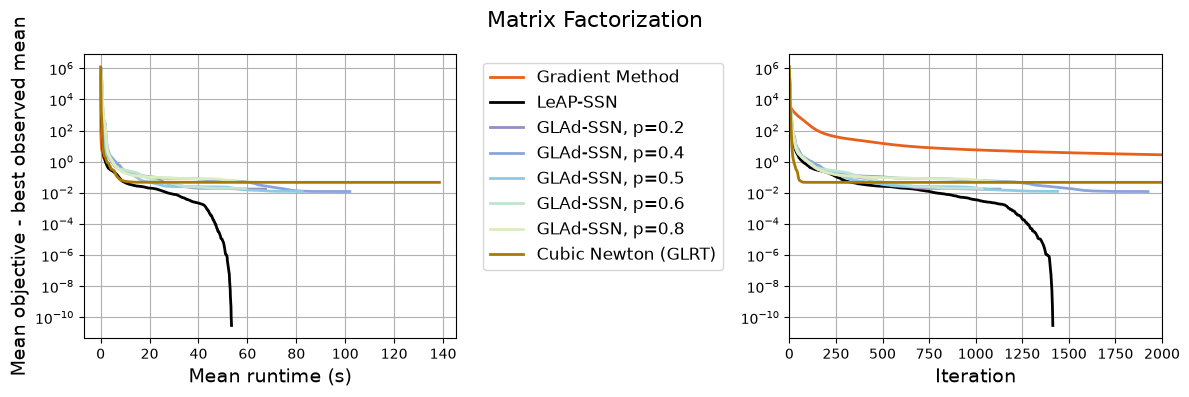

Last Mean gradient norm of Gradient Method: 0.6846770415394948
Last Mean gradient norm of LeAP-SSN: 3.073151761030878e-08
Last Mean gradient norm of GLAd-SSN, p=0.2: 2.9402670689041847e-08
Last Mean gradient norm of GLAd-SSN, p=0.4: 2.723111021145903e-08
Last Mean gradient norm of GLAd-SSN, p=0.5: 5.527013153565825e-08
Last Mean gradient norm of GLAd-SSN, p=0.6: 8.809100087673394e-09
Last Mean gradient norm of GLAd-SSN, p=0.8: 4.931621447519494e-10
Last Mean gradient norm of Cubic Newton (GLRT): 1.6662949418342412e-13


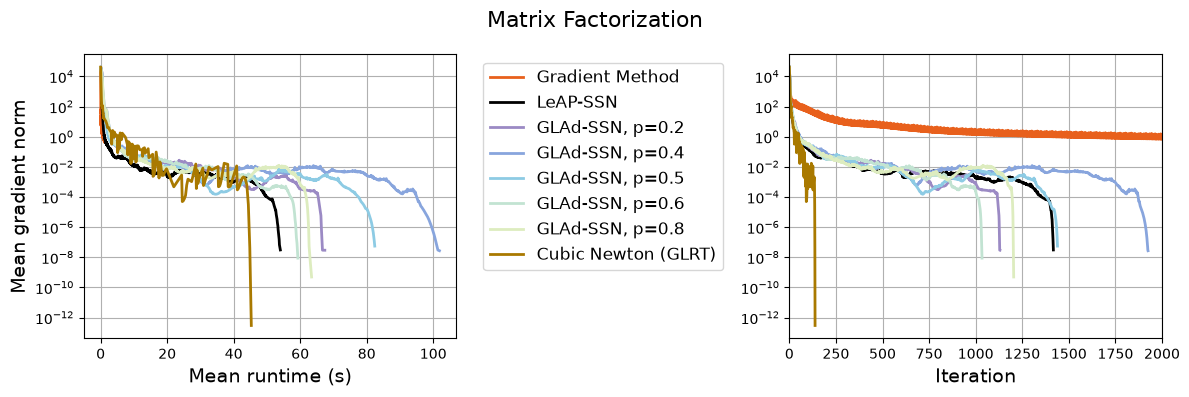

Last Mean penalty of Gradient Method: 0.09771572276576726
Last Mean penalty of LeAP-SSN: 0.00024173124593046004
Last Mean penalty of GLAd-SSN, p=0.2: 0.0013115309246545333
Last Mean penalty of GLAd-SSN, p=0.4: 0.0009580710188380372
Last Mean penalty of GLAd-SSN, p=0.5: 0.0009795752450748366
Last Mean penalty of GLAd-SSN, p=0.6: 0.0015243760180493528
Last Mean penalty of GLAd-SSN, p=0.8: 0.003295711891255272
Last Mean penalty of Cubic Newton (GLRT): 0.003189423595537127


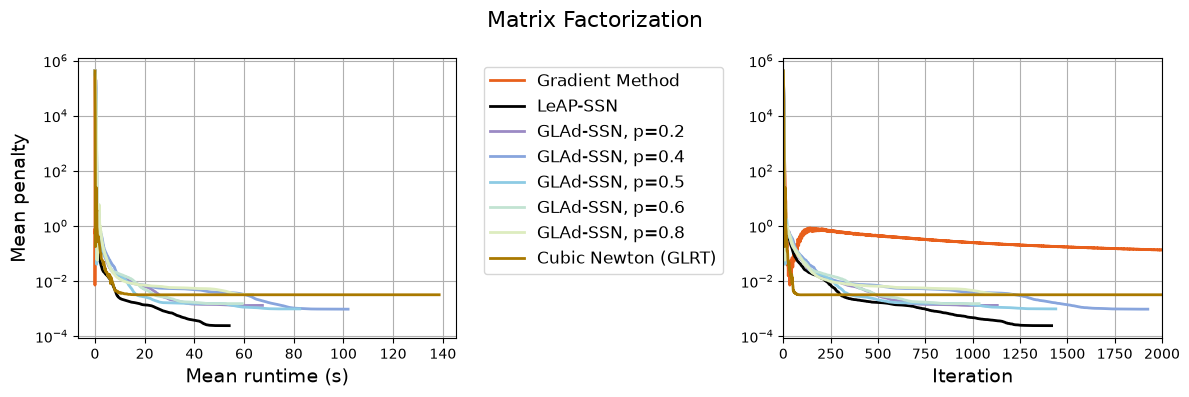

In [ ]:
figures["func"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=mn_func, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="func", which_measure_2="func",
    ylabel="Mean objective - best observed mean",
)
plt.show()
plt.close(figures["func"])


figures["grad_norm"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=0, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="grad_norm", which_measure_2="grad_norm",
    ylabel="Mean gradient norm",
)
plt.show()
plt.close(figures["grad_norm"])


figures["penalty"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=0, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="penalty", which_measure_2="penalty",
    ylabel="Mean penalty",
)
plt.show()
plt.close(figures["penalty"])

## Additional comparison: exact Hessian and Gauss-Newton

Keep gradient descent and nonconvex cubic Newton as baselines, then compare LeAP and the selected GLAd
exponents. Solid lines use the exact generalized Hessian; dashed lines use
Gauss-Newton, with the same color for each pair. All curves use the same seed
data and starting factors. The objective reference is the best observed mean
among the methods shown in these additional plots, not a known global optimum.
The three original plots above keep their own reference.


Last Mean objective - best observed mean of Gradient Method: 1.8757852622748032
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.04718860426964966
Last Mean objective - best observed mean of LeAP-SSN (exact): 0.0
Last Mean objective - best observed mean of LeAP-SSN (GN): 0.18265103850990272
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (exact): 0.017276198537729215
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (GN): 0.4824809866531723
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (exact): 0.012492597939854022
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (GN): 0.2731358619421371


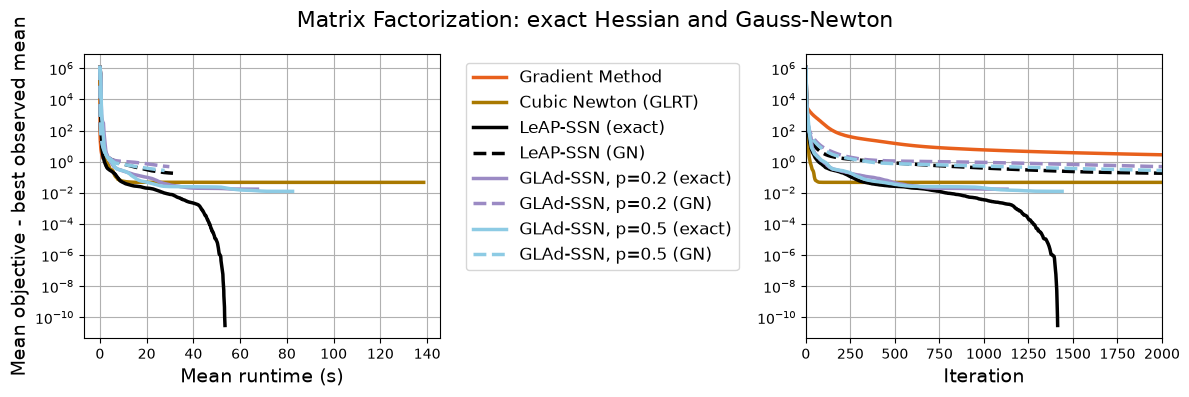

Last Mean gradient norm of Gradient Method: 0.6846770415394948
Last Mean gradient norm of Cubic Newton (GLRT): 1.6662949418342412e-13
Last Mean gradient norm of LeAP-SSN (exact): 3.073151761030878e-08
Last Mean gradient norm of LeAP-SSN (GN): 0.029615494461562874
Last Mean gradient norm of GLAd-SSN, p=0.2 (exact): 2.9402670689041847e-08
Last Mean gradient norm of GLAd-SSN, p=0.2 (GN): 0.05589010468761389
Last Mean gradient norm of GLAd-SSN, p=0.5 (exact): 5.527013153565825e-08
Last Mean gradient norm of GLAd-SSN, p=0.5 (GN): 0.05469741900090742


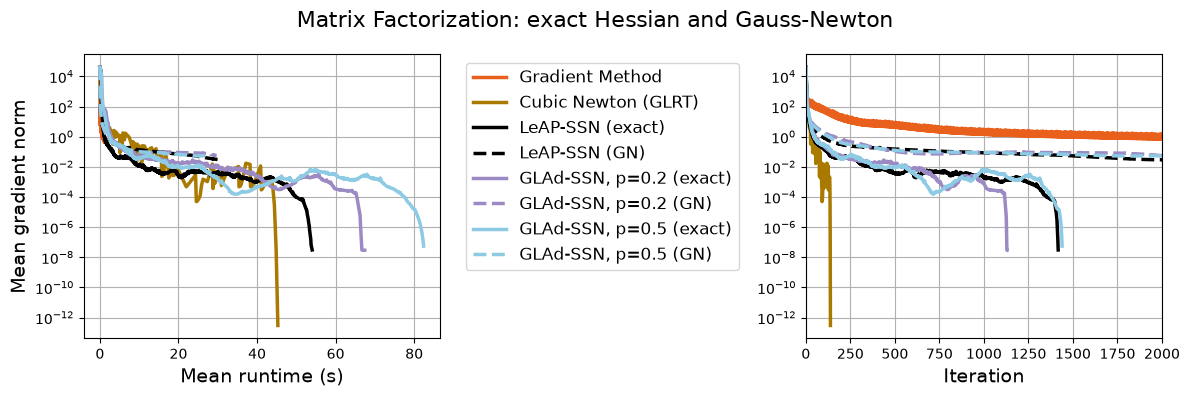

Last Mean penalty of Gradient Method: 0.09771572276576726
Last Mean penalty of Cubic Newton (GLRT): 0.003189423595537127
Last Mean penalty of LeAP-SSN (exact): 0.00024173124593046004
Last Mean penalty of LeAP-SSN (GN): 0.007330632160109773
Last Mean penalty of GLAd-SSN, p=0.2 (exact): 0.0013115309246545333
Last Mean penalty of GLAd-SSN, p=0.2 (GN): 0.024624158105557927
Last Mean penalty of GLAd-SSN, p=0.5 (exact): 0.0009795752450748366
Last Mean penalty of GLAd-SSN, p=0.5 (GN): 0.01299716957257499


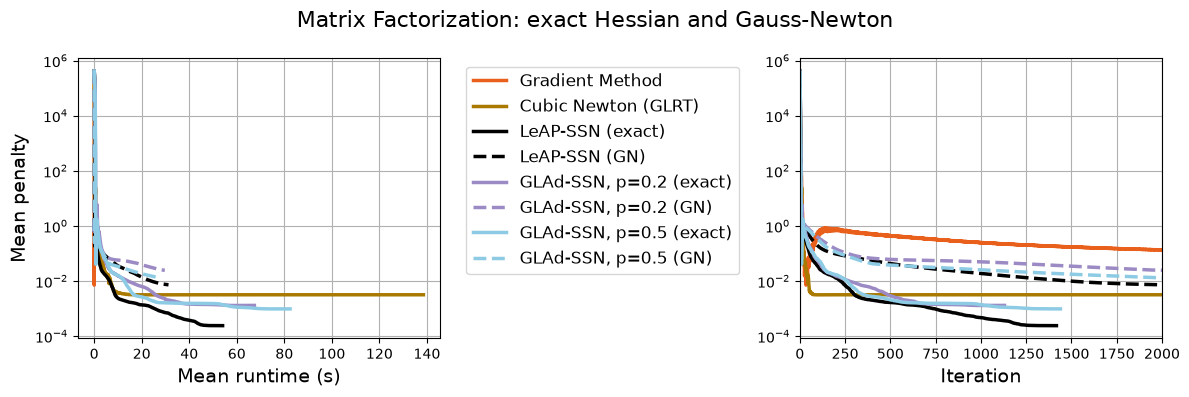

In [ ]:
# Select matching exact/Gauss-Newton pairs without changing the original plots.
comparison_names = ["Gradient Method", "Cubic Newton (GLRT)"]
comparison_colors = [colors[0], colors[original_method_names.index("Cubic Newton (GLRT)")]]
comparison_styles = ["-", "-"]
for method_name in gn_base_names:
    color = colors[original_method_names.index(method_name)]
    comparison_names.extend([method_name, f"{method_name} (GN)"])
    comparison_colors.extend([color, color])
    comparison_styles.extend(["-", "--"])

comparison_histories = [averaged_history[name] for name in comparison_names]
comparison_labels = [
    name if name in ("Gradient Method", "Cubic Newton (GLRT)") or name.endswith(" (GN)") else f"{name} (exact)"
    for name in comparison_names
]
comparison_reference = min(np.min(history["func"]) for history in comparison_histories)

for measure, reference, ylabel in [
    ("func", comparison_reference, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        comparison_histories, comparison_labels,
        colors=comparison_colors, linewidths=[2.5] * len(comparison_names),
        linestyles=comparison_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization: exact Hessian and Gauss-Newton",
        max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[f"{measure}_gn"] = fig
    plt.show()
    plt.close(fig)


## Optional figure export

Set `SAVE_FIGURES=True` to save all six PDFs in a new, Git-ignored local folder.
By default, the notebook only displays the plots.

In [ ]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "_diagnostics_archive" / "multiple_cubic_new" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    for measure, fig in figures.items():
        fig.savefig(output_dir / f"{measure}.pdf", bbox_inches="tight")
    print("Saved figures to", output_dir)

## Additional gradient plots: mean and typical behavior

For each method, compare the **arithmetic mean** (left) with **individual
seed traces, the median, and the 25th-75th percentile band** (right), against
iteration on a logarithmic gradient axis. The band describes variation across
seeds, not a confidence interval. With one seed, mean and median coincide and
the band has zero width. A median curve is a pointwise summary, not a solver
trajectory or evidence by itself of a convergence rate.

Run the following two cells after collecting `all_seeds_histories`; there is
no need to rerun the solvers or the earlier plotting cells. They read
`all_seeds_histories[seed][method]["grad_norm"]` directly and retain the new
figures separately in `gradient_seed_figures`. The six existing plots and
their export cell above are unchanged.

Every individual trace extends to its recorded endpoint within the selected
iteration window. Mean, median, and percentiles include **every seed**, so
these summaries end at the shortest run; a dotted line marks this boundary
when other runs continue. No final values are padded and no stopped seeds
are silently dropped. Unlike the earlier plots, these displays do not trim
at `plot_threshold`, so later rebounds remain visible. Exact zeros are omitted
from the logarithmic display; all positive recorded values are retained.
The methods share axis limits. Set `gradient_summary_max_iter` to a smaller
value to zoom into the local phase, or to `None` for the full recorded range.

These are additional diagnostics for the same MF experiment in Section 5.2 /
Appendix E.2 of [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1), rather
than reproductions of an additional paper figure. They use the current run's
seeds and settings and do not change the objective, algorithms, initialization,
subproblem solves, tolerances, or stopping criteria.


In [ ]:
def plot_gradient_seed_summary(seed_histories, method_name, *, max_iter=None, ylim=None):
    """Compare mean and typical full-gradient norms for one MF method.

    seed_histories maps seeds to method histories; each ``grad_norm`` must
    be a finite, nonnegative 1-D array with the initial point at index zero.
    max_iter is an inclusive display limit, not a solver stopping criterion.
    All-seed summaries use common recorded iterations. Individual traces
    keep their own lengths. Zero values are masked only for the log display.
    Return a figure without modifying any input history or saving files.
    """
    runs = []
    for seed, method_histories in seed_histories.items():
        values = np.asarray(method_histories[method_name]["grad_norm"], dtype=float)
        if (values.ndim != 1 or values.size == 0
                or not np.all(np.isfinite(values)) or np.any(values < 0)):
            raise ValueError(f"Invalid gradient history for {method_name}, seed {seed}.")
        if max_iter is not None:
            if not isinstance(max_iter, (int, np.integer)) or max_iter < 0:
                raise ValueError("max_iter must be a nonnegative integer or None.")
            values = values[:max_iter + 1]
        runs.append(values)
    if not runs:
        raise ValueError("Collect at least one seed history before plotting.")

    common_length = min(map(len, runs))
    longest_length = max(map(len, runs))
    gradients = np.stack([values[:common_length] for values in runs])
    mean = np.mean(gradients, axis=0)
    median = np.median(gradients, axis=0)
    lower, upper = np.percentile(gradients, [25, 75], axis=0)
    iterations = np.arange(common_length)

    def positive(values):
        return np.where(values > 0, values, np.nan)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True,
                             layout="constrained")
    fig.suptitle(f"{method_name}: gradient norms across {len(runs)} seed(s)")
    axes[0].plot(iterations, positive(mean), color="#1f2937", linewidth=2.3,
                 marker="." if common_length == 1 else None, label="Arithmetic mean")
    axes[0].set_title("Mean")
    for index, values in enumerate(runs):
        axes[1].plot(np.arange(len(values)), positive(values), color="#8896a8",
                     alpha=0.45, linewidth=0.9,
                     marker="." if len(values) == 1 else None,
                     label="Individual seeds" if index == 0 else "_nolegend_")
    axes[1].fill_between(iterations, positive(lower), positive(upper),
                         color="#2563eb", alpha=0.22, label="25th-75th percentile")
    axes[1].plot(iterations, positive(median), color="#2563eb", linewidth=2.3,
                 marker="." if common_length == 1 else None, label="Median")
    axes[1].set_title("Typical behavior and individual seeds")

    for ax in axes:
        ax.set_yscale("log")
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Gradient norm")
        ax.set_xlim(0, max(1, longest_length - 1 if max_iter is None else max_iter))
        if ylim is not None:
            ax.set_ylim(ylim)
        if common_length < longest_length:
            ax.axvline(common_length - 1, color="#777777", linestyle=":",
                       linewidth=1, label="All-seed summary ends")
        ax.grid(True, which="major", alpha=0.2)
        ax.legend(fontsize=9)
    if any(np.any(values == 0) for values in runs):
        fig.supxlabel("Exact zeros are omitted from the logarithmic display", fontsize=9)
    return fig


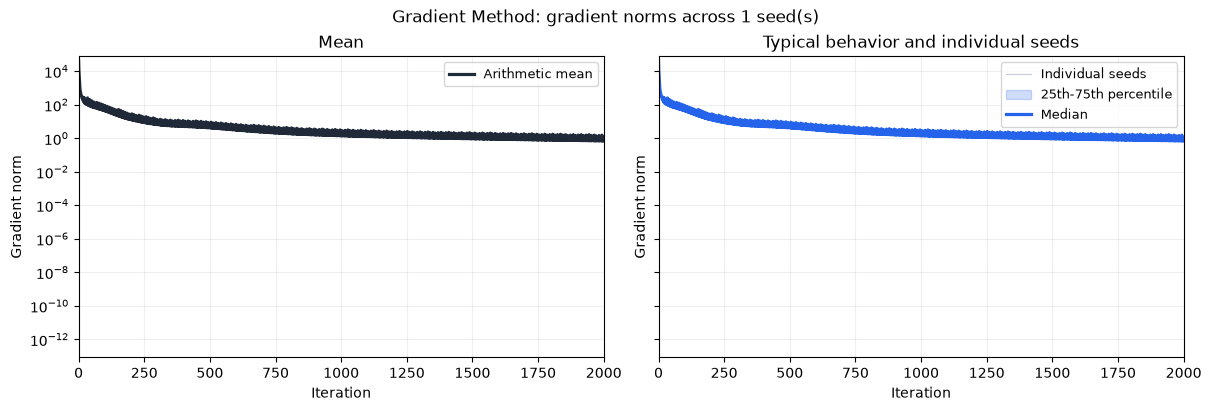

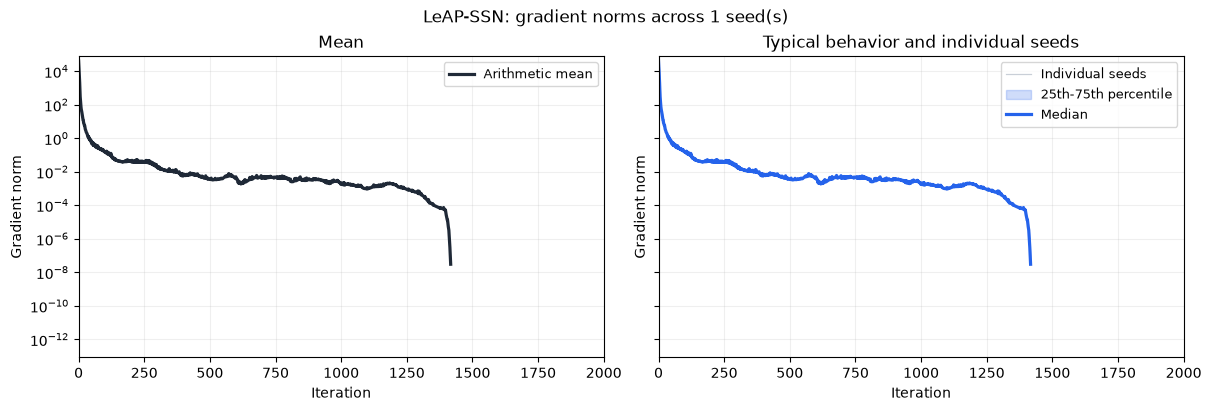

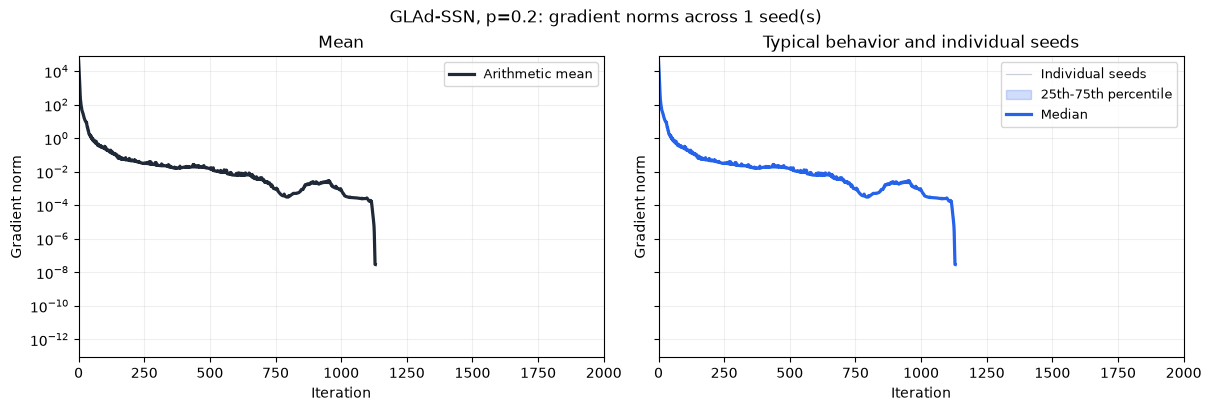

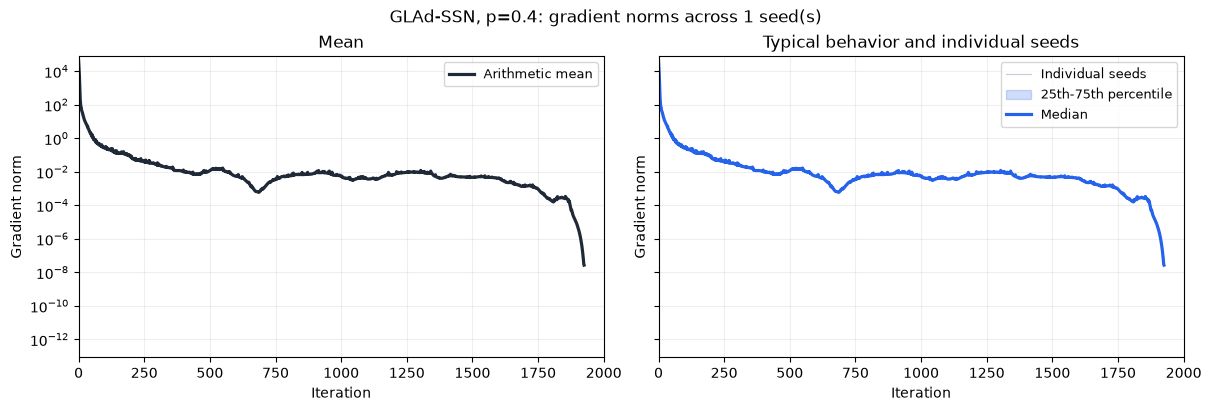

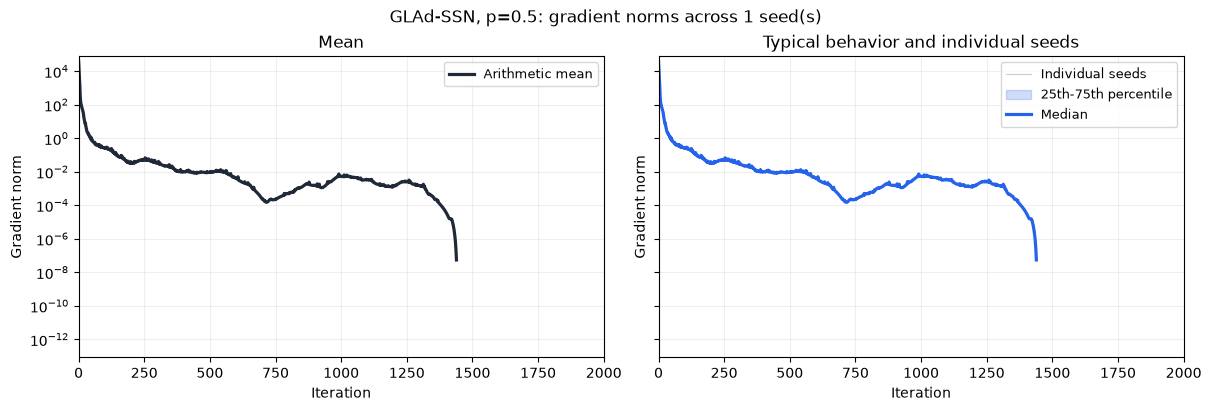

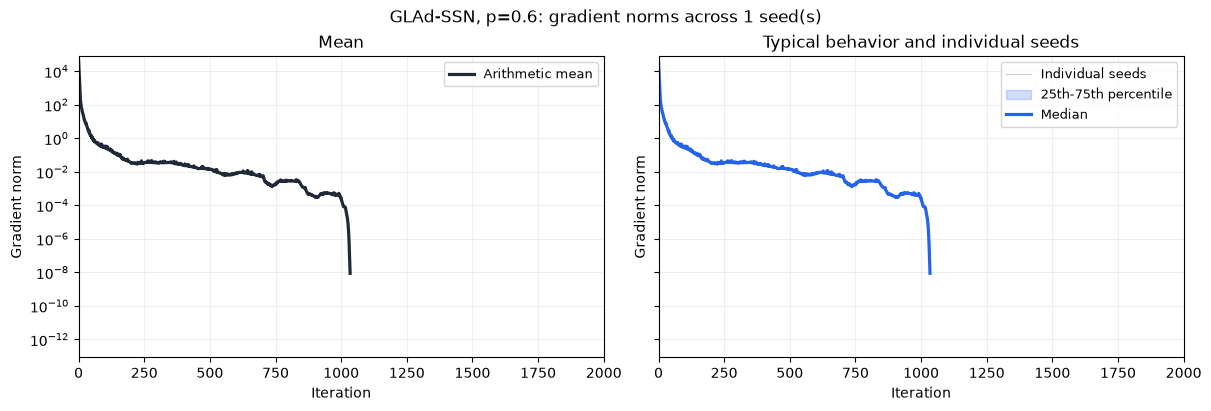

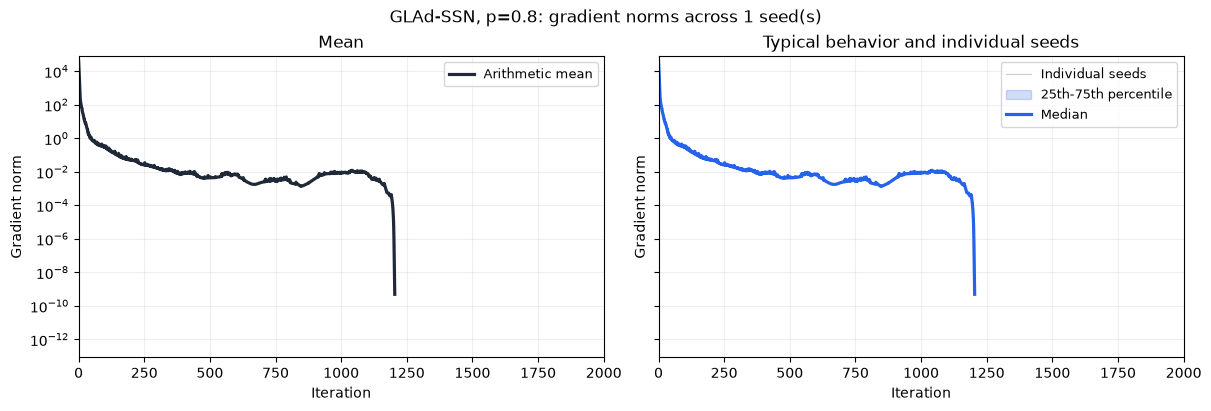

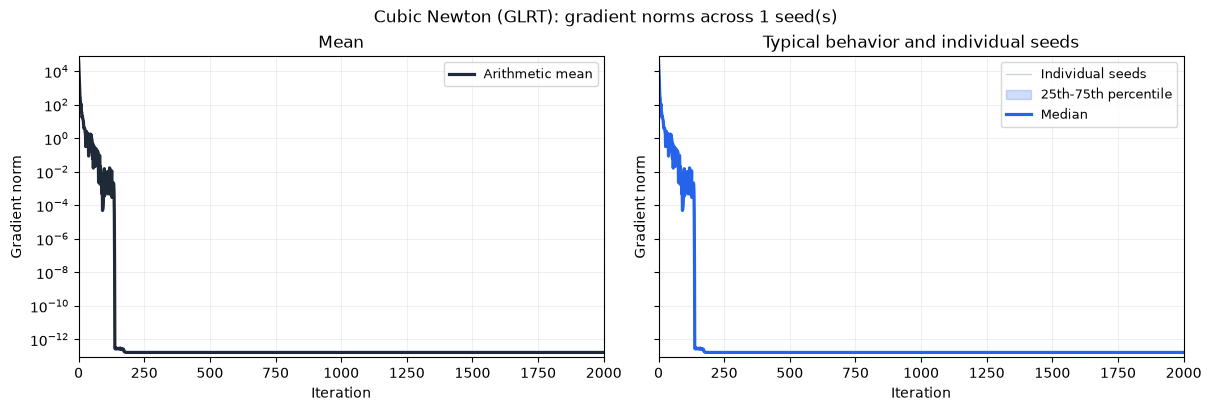

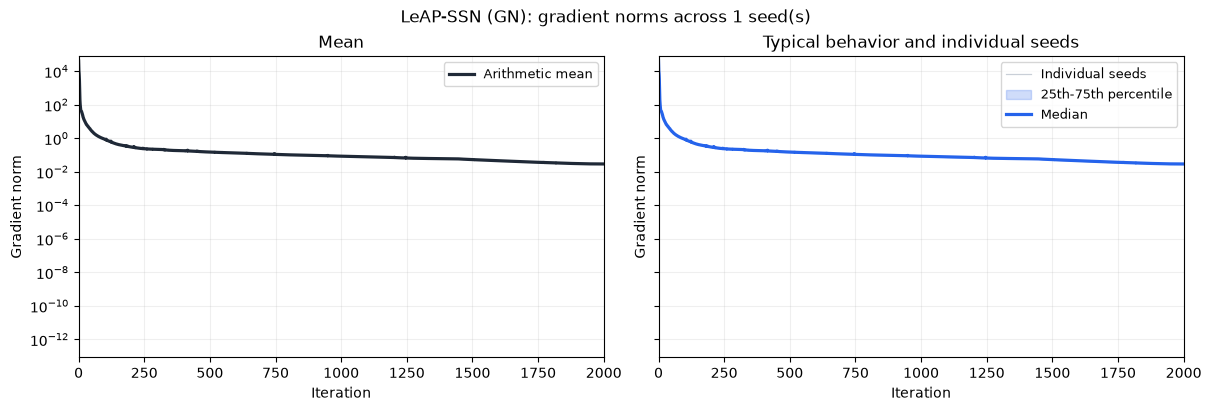

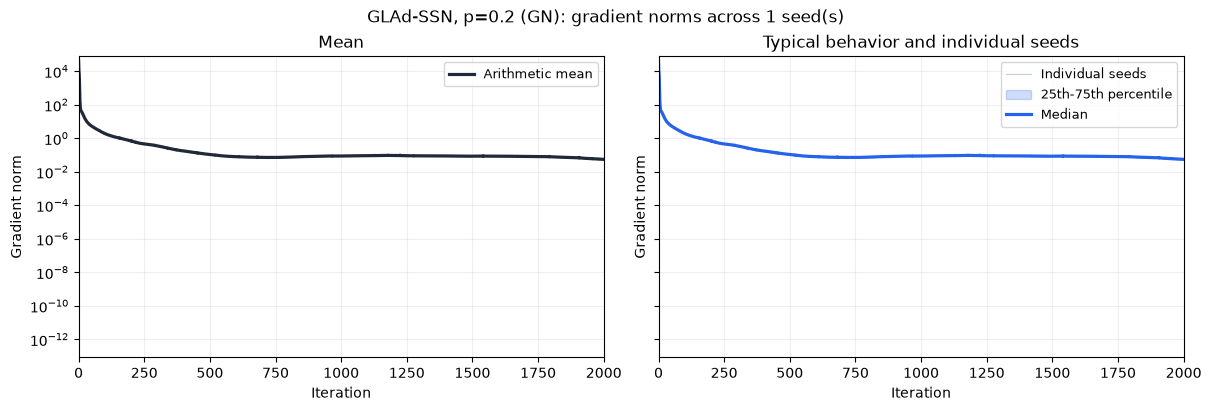

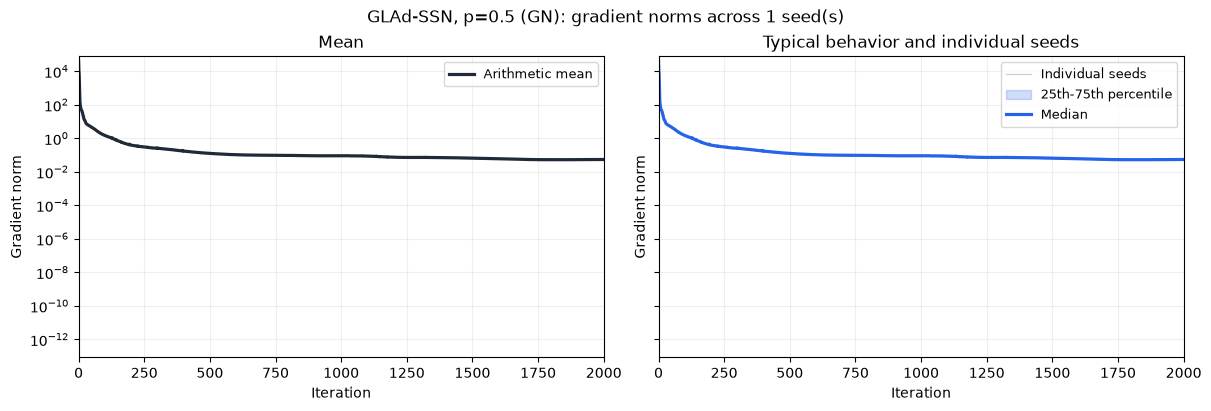

In [ ]:
# Select any subset of method names here; the default includes the GN runs.
gradient_summary_methods = list(next(iter(all_seeds_histories.values())))
gradient_summary_max_iter = number_of_iterations  # e.g. 40 for a zoom; None for all.

# Common axis limits across methods, computed from the displayed observations.
gradient_summary_positive_extents = []
gradient_summary_last_iteration = 0
for gradient_method_name in gradient_summary_methods:
    for gradient_method_histories in all_seeds_histories.values():
        gradient_values = np.asarray(gradient_method_histories[gradient_method_name]["grad_norm"])
        if gradient_summary_max_iter is not None:
            gradient_values = gradient_values[:gradient_summary_max_iter + 1]
        gradient_summary_last_iteration = max(gradient_summary_last_iteration, len(gradient_values) - 1)
        gradient_positive_values = gradient_values[np.isfinite(gradient_values) & (gradient_values > 0)]
        if gradient_positive_values.size:
            gradient_summary_positive_extents.append(
                (gradient_positive_values.min(), gradient_positive_values.max())
            )
gradient_summary_ylim = (
    (0.5 * min(pair[0] for pair in gradient_summary_positive_extents),
     2.0 * max(pair[1] for pair in gradient_summary_positive_extents))
    if gradient_summary_positive_extents else (1e-16, 1.0)
)
gradient_summary_xlim = (gradient_summary_last_iteration
                         if gradient_summary_max_iter is None else gradient_summary_max_iter)

gradient_seed_figures = {}
for gradient_method_name in gradient_summary_methods:
    gradient_fig = plot_gradient_seed_summary(
        all_seeds_histories, gradient_method_name,
        max_iter=gradient_summary_xlim, ylim=gradient_summary_ylim,
    )
    gradient_seed_figures[gradient_method_name] = gradient_fig
    plt.show()
    plt.close(gradient_fig)


## Combined gradient comparison: GLAd, cubic Newton, and gradient descent

The next two cells add **two separate figures**, one against iteration and one
against runtime, using the existing `all_seeds_histories`. Each overlays the
selected methods: thick colored medians, matching 25th-75th percentile bands,
and faint individual seed traces. GLAd defaults to `p=0.5`; edit
`combined_gradient_methods` to select another exponent or add methods.

The iteration view defaults to the first 150 iterations (or the configured
Newton budget if smaller). Set `combined_gradient_max_iter=None` for the full
recorded range. The runtime view uses the full recorded range by default;
`combined_gradient_max_time` can limit it in seconds. These are display limits
only. Both figures use the same gradient scale. They are stored separately in
`combined_gradient_figures`, and do not change the earlier figures or exports.

At each iteration, summaries use the same iteration from every seed. For
runtime, each method uses a common grid of its observed timestamps over the
interval covered by **all** its seeds, taking the latest recorded gradient
at or before each time (steps, without interpolating between gradient values).
Repeated timestamps use their last observation. Recorded times include any
failure work included by the solver in its final timestamp.

An open circle marks the last median value supported by every seed. Individual
traces continue to their own endpoints within the display window. No values
are carried beyond a run's final timestamp/iteration and no terminated seed
is dropped from a summary. Thus an early cubic termination can still shorten
its median and band; the visible individual tails show the remaining runs.
The band shows seed variability, not a confidence interval. Exact zeros are
omitted on the logarithmic axis, and no `plot_threshold` truncation is applied.

These are additional diagnostics of the Section 5.2 / Appendix E.2 MF
experiment in [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1), using
`all_seeds_histories[seed][method]["grad_norm"]` and `["time"]` from this
notebook's run cell. They do not reproduce an additional published figure.
The current run's seeds, objective, algorithms, subproblem controls, and
stopping criteria are unchanged. No solver rerun is needed if those histories
are still in the kernel.


In [ ]:
def plot_combined_gradient_histories(seed_histories, method_colors, *,
                                     axis="iteration", max_x=None, ylim=None):
    """Overlay per-seed norms, medians and quartiles for selected MF methods.

    seed_histories maps each seed to method histories. ``grad_norm`` and
    ``time`` are equal-length 1-D arrays, starting with the initial point;
    times are cumulative seconds, finite, nonnegative and nondecreasing.
    method_colors maps selected method names to Matplotlib colors.
    axis is 'iteration' or 'runtime'; max_x is an optional inclusive display
    bound in those units. All-seed summaries use common recorded support.
    Runtime uses the latest observation at each common timestamp, including
    the last observation at duplicate times, with no endpoint extrapolation.
    Return a new figure; leave all input histories and earlier plots intact.
    """
    if axis not in ("iteration", "runtime"):
        raise ValueError("axis must be 'iteration' or 'runtime'.")
    if not seed_histories or not method_colors:
        raise ValueError("Select at least one method and collect seed histories first.")
    if max_x is not None and (not np.isfinite(max_x) or max_x < 0):
        raise ValueError("max_x must be finite and nonnegative, or None.")

    runs_by_method = {}
    for method in method_colors:
        runs = []
        for seed, histories_for_seed in seed_histories.items():
            history = histories_for_seed[method]
            g = np.asarray(history["grad_norm"], dtype=float)
            t = np.asarray(history["time"], dtype=float)
            if (g.ndim != 1 or g.size == 0 or t.shape != g.shape
                    or not np.all(np.isfinite(g)) or np.any(g < 0)
                    or not np.all(np.isfinite(t)) or np.any(t < 0)
                    or np.any(np.diff(t) < 0)):
                raise ValueError(f"Invalid gradient/time history for {method}, seed {seed}.")
            runs.append((np.arange(g.size) if axis == "iteration" else t, g))
        runs_by_method[method] = runs

    def positive(values):
        return np.where(values > 0, values, np.nan)

    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    zero_present = False
    no_overlap = []
    for method, color in method_colors.items():
        runs = runs_by_method[method]
        for x, g in runs:
            ax.plot(x, positive(g), color=color, alpha=0.18, linewidth=0.8,
                    drawstyle="steps-post" if axis == "runtime" else "default",
                    marker="." if len(g) == 1 else None, label="_nolegend_")
            zero_present |= bool(np.any(g == 0))

        start = max(x[0] for x, _ in runs)
        end = min(x[-1] for x, _ in runs)
        if max_x is not None:
            end = min(end, max_x)
        if start > end:
            no_overlap.append(method)
            ax.plot([], [], color=color, linewidth=2.3, label=f"{method} (traces only)")
            continue

        if axis == "iteration":
            grid = np.arange(int(end) + 1)
            values = np.stack([g[:len(grid)] for _, g in runs])
        else:
            # Every change inside common support appears in the step summary.
            grid = np.unique(np.concatenate(
                [x[(x >= start) & (x <= end)] for x, _ in runs]
                + [np.array([start, end])]
            ))
            values = np.stack([
                g[np.searchsorted(x, grid, side="right") - 1] for x, g in runs
            ])
        lower, median, upper = np.percentile(values, [25, 50, 75], axis=0)
        ax.fill_between(grid, positive(lower), positive(upper), color=color,
                        alpha=0.16, step="post" if axis == "runtime" else None)
        ax.plot(grid, positive(median), color=color, linewidth=2.4, label=method,
                drawstyle="steps-post" if axis == "runtime" else "default")
        if median[-1] > 0:
            ax.plot(grid[-1], median[-1], marker="o", markersize=5,
                    markerfacecolor="white", markeredgecolor=color,
                    linestyle="none", label="_nolegend_")

    longest = max(x[-1] for runs in runs_by_method.values() for x, _ in runs)
    right = longest if max_x is None else max_x
    ax.set_xlim(0, right if right > 0 else 1)
    ax.set_yscale("log")
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("Iteration" if axis == "iteration" else "Runtime (s)")
    ax.set_ylabel("Gradient norm")
    fig.suptitle(f"Matrix factorization: {len(seed_histories)} seeds, gradient vs {axis}")
    ax.set_title("Thick: median | Shaded: 25th-75th percentile | Faint: individual seeds",
                 fontsize=10)
    ax.legend(fontsize=10)
    ax.grid(True, which="major", alpha=0.2)
    note = "Open circles: end of each all-seed summary."
    if no_overlap:
        note += " No common recorded interval: " + ", ".join(no_overlap) + "."
    if zero_present:
        note += " Exact zeros omitted on the log axis."
    fig.supxlabel(note, fontsize=9)
    return fig


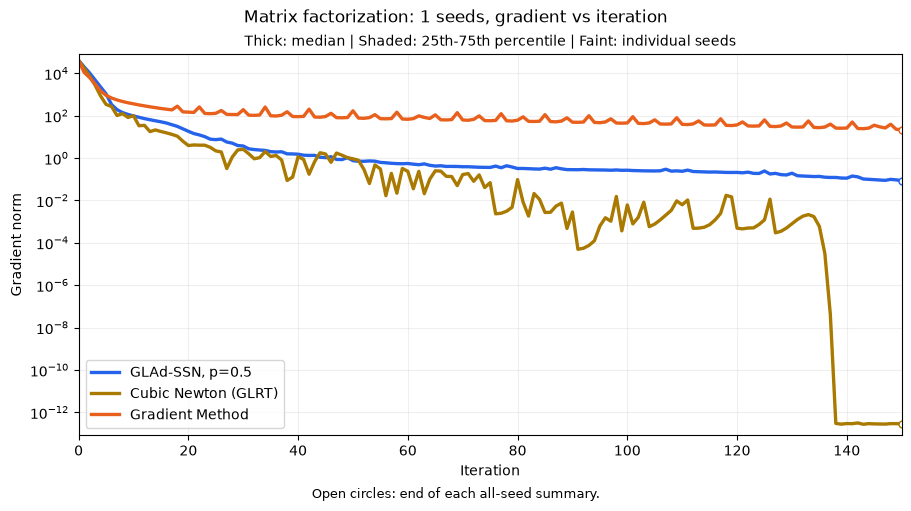

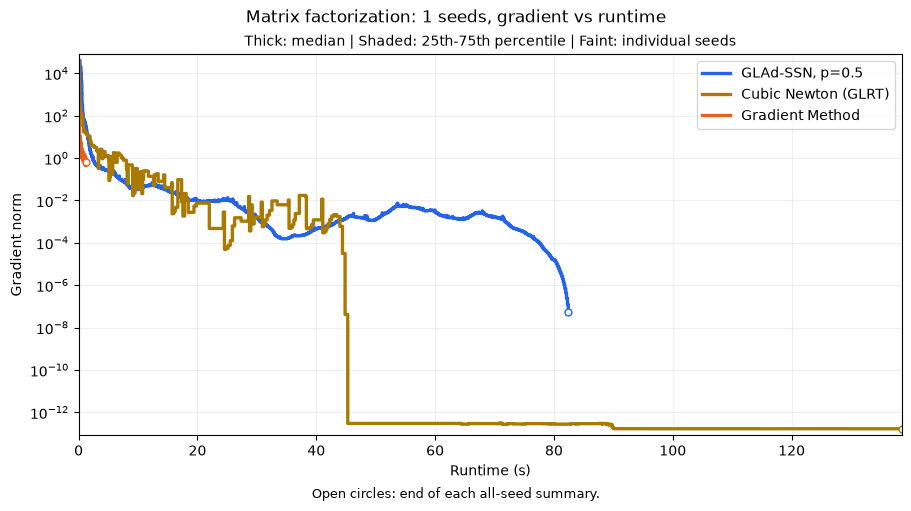

In [ ]:
# Change the GLAd key to select another exponent, or add another method/color.
combined_gradient_methods = {
    "GLAd-SSN, p=0.5": "#2563eb",
    "Cubic Newton (GLRT)": "#A97900",
    "Gradient Method": "#E8601C",
}
combined_gradient_max_iter = min(number_of_iterations, 150)  # None: full range.
combined_gradient_max_time = None  # Optional runtime display limit in seconds.

# Share the gradient scale between the iteration and runtime figures.
combined_gradient_extents = []
for combined_seed_histories in all_seeds_histories.values():
    for combined_method in combined_gradient_methods:
        combined_values = np.asarray(combined_seed_histories[combined_method]["grad_norm"])
        combined_positive = combined_values[np.isfinite(combined_values) & (combined_values > 0)]
        if combined_positive.size:
            combined_gradient_extents.append((combined_positive.min(), combined_positive.max()))
combined_gradient_ylim = (
    (0.5 * min(pair[0] for pair in combined_gradient_extents),
     2.0 * max(pair[1] for pair in combined_gradient_extents))
    if combined_gradient_extents else (1e-16, 1.0)
)

combined_gradient_figures = {}
for combined_axis, combined_limit in [
    ("iteration", combined_gradient_max_iter),
    ("runtime", combined_gradient_max_time),
]:
    combined_fig = plot_combined_gradient_histories(
        all_seeds_histories, combined_gradient_methods,
        axis=combined_axis, max_x=combined_limit, ylim=combined_gradient_ylim,
    )
    combined_gradient_figures[combined_axis] = combined_fig
    plt.show()
    plt.close(combined_fig)
